# Analyze of the dataset provided

------------------------------------

### Initializing the work environment

```bash
python -m venv venv
source venv/bin/activate
pip install -r requirement.txt
```

### Import the necessary libs

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

--------------------------------------------

The dataset consists of 3 columns: ID, a secret color, and the testimony. The color will be used to check if our clusters are accurate at the end of the learning phase of our project.

Our objective is to group similar testimonies into clusters, where each cluster potentially corresponds to a specific diagnosis or underlying disease.

In [100]:
def init(path):
    df = pd.read_csv(path, header=None, names=[0, 1, 2])
    print(f"dataset load perfectly : {df.shape}")
    return df

In [101]:
# function for print the dataset (debug or visualization purpose)
def print_df(n, df):
    df_print = df.head(n)
    print(f"this is the {n} first lines of the dataset:\n\n{df_print}")

-------------------------------

## Dataset analysis

In this notebook, our goal is to understand the data within our dataset as thoroughly as possible. To achieve this, graphical representations and data visualization will be our best tools. This section does not include any machine learning algorithms; it focuses entirely on how our data can be visually interpreted to serve our objective.

### First step : The text average length

We will determine the length of the longest and shortest testimonies, as well as calculate the average word count per patient.

In [102]:
def mean_testimonie(df):
    words_array = df[2][1:].str.split().str.len()
    max_len = words_array.max()
    min_len = words_array.min()
    mean_len = words_array.mean()

    print("Testimony Length Analysis : ")
    print(f"    Longest testimony : {max_len} words")
    print(f"    Shortest testimony : {min_len} words")
    print(f"    Average testimony : {mean_len:.2f} words")

df = init("./cleaned_dataset.csv")
mean_testimonie(df)

dataset load perfectly : (1012, 3)
Testimony Length Analysis : 
    Longest testimony : 59 words
    Shortest testimony : 13 words
    Average testimony : 28.69 words


We can observe that the variance in text lengths is not too large. Therefore, no further changes or filtering are needed for this part.

### Second step : the vocabulary analysis

We are now going to make a function will show us the most used words, and afterward, we can analyze the results to know what to do with our dataset.

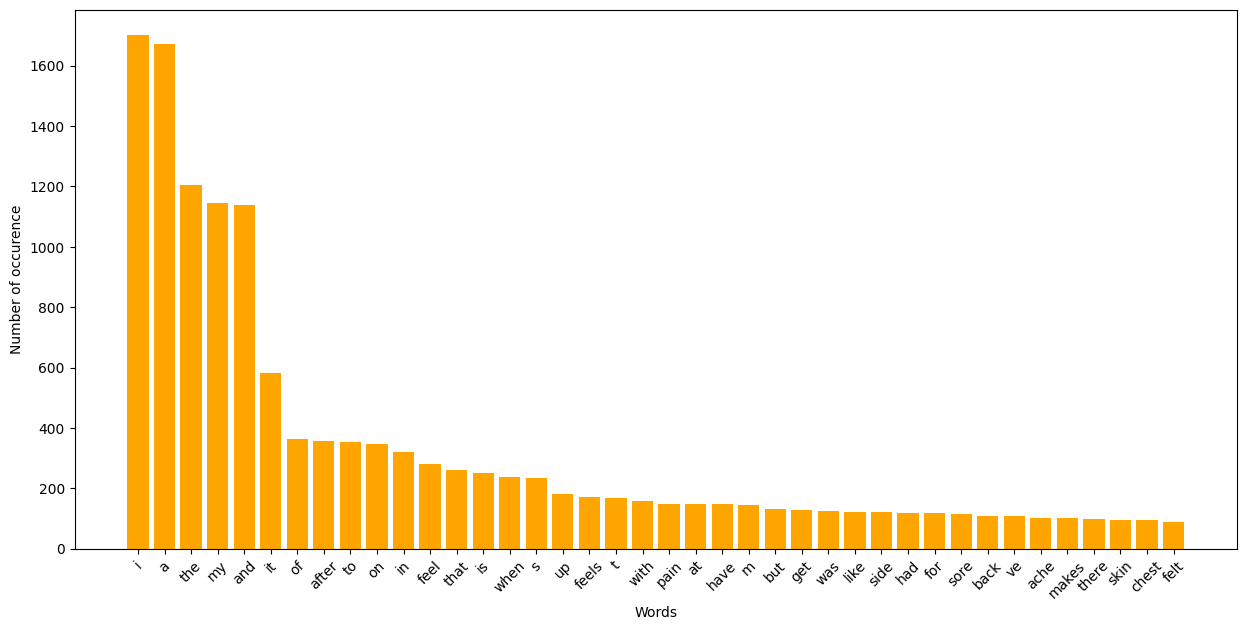

In [103]:
def most_present_words(df, num=40):
    words_array = df[2].str.split() # create an arry for each line
    all_words_array = words_array.explode() # create an array with all the words
    frequence = all_words_array.value_counts().head(num) # will be count and classify the words per occurence
    
    plt.figure(figsize=(15, 7))
    plt.bar(frequence.index, frequence.values, color="orange")
    plt.xlabel("Words")
    plt.xticks(rotation=45)
    plt.ylabel("Number of occurence")
    plt.show()


most_present_words(df)

We can see that the most written words are useless for the training because the model wants words with a real meaning, like a location or a feeling. We don't need words like 'I', 'my', 'and', etc.

In [104]:
fantomes = ["s", "t", "m", "ve", "d", "ll", "re", "don", "didn", "doesn"]
storytelling = ["feel", "feels", "feeling", "felt", "notice", "noticed", "think", "thought", "believe", "start", "started", "keep", "kept", "got", "get", "went", "go", "came", "come", "make", "made", "like", "just", "gives", "makes", "long", "bit", "night", "turning"]
stop_words_finaux = set(list(ENGLISH_STOP_WORDS) + fantomes + storytelling)

# 1. Ta fonction de nettoyage (qui marche très bien !)
def clean_single_text(text):
    if not isinstance(text, str):
        return text
    words = text.lower().split() 
    cleaned_words = [word for word in words if word not in stop_words_finaux] 
    return " ".join(cleaned_words) 

# 2. On applique le nettoyage sur TOUTE la colonne
df[2] = df[2].apply(clean_single_text)

# 3. LE KILLER DE FANTÔME : 
# Si la première ligne contient le chiffre "2" (le faux titre), on la supprime sans pitié !
if str(df[2].iloc[0]).strip() == "2":
    df = df.drop(index=0).reset_index(drop=True)

# On affiche
print_df(10, df)

this is the 10 first lines of the dataset:

    0         1                                                  2
0   1  0x000000  uneven paths heel wobbly slanted pavements bri...
1   2  0x000000  feverish eased breathing faster dry exhausting...
2   3  0x000000  working garden touched metal grill stove left ...
3   4  0x000000  short sprint brought twinge middle thigh tende...
4   5  0x000000  accidentally left hand hot mug minute tender s...
5   6  0x000000  sudden twist reaching bag lower switched sore ...
6   7  0x000000  birthday party hot beverage knocked area red t...
7   8  0x000000  rash forearms handling new brand sunscreen spo...
8   9  0x000000  lost pounds headaches lessened lightheaded sta...
9  10  0x000000  rash face jaw classic hives appearance raised ...


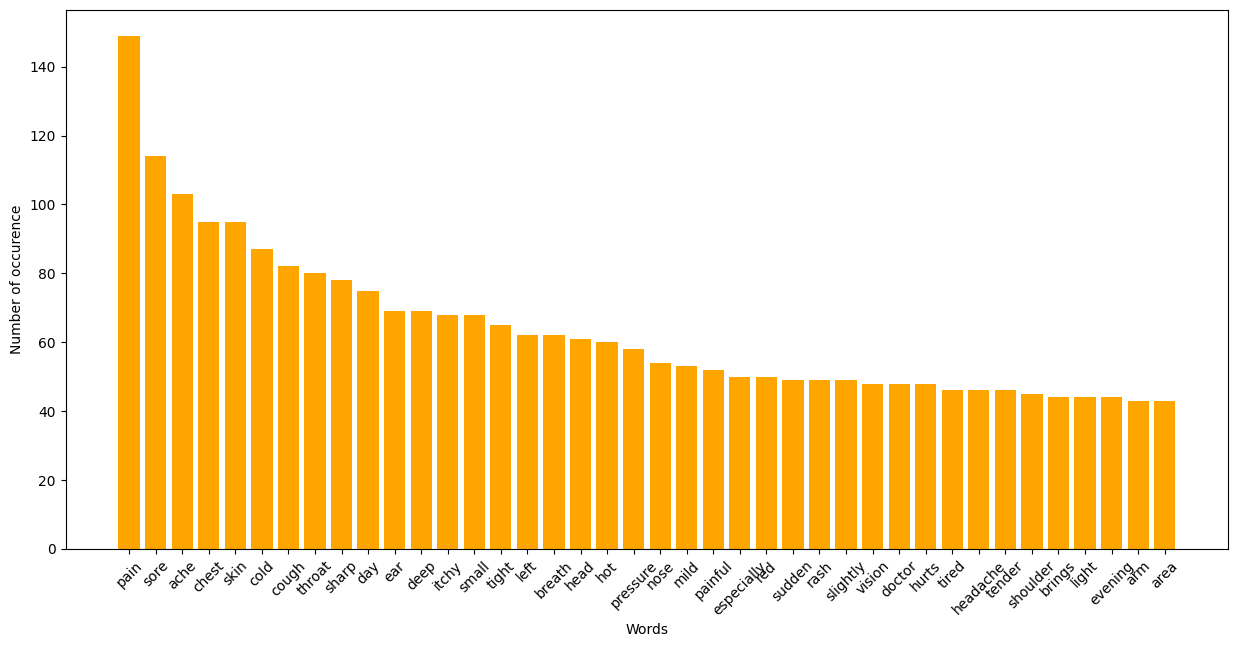

In [105]:
most_present_words(df)

We can now see that the remaining words make much more sense than before this additional cleaning. We are left with highly specific words used in a strictly medical context. This vocabulary will be extremely useful for our machine learning algorithms.

In [106]:
df.to_csv("cleaned_dataset.csv", index=False)